# AutoCoda Cross-Asset vs SPY Across Multiple Horizons

This notebook tests whether the **1x-capital, cross-asset AutoCoda allocator** beats **1x SPY buy & hold** across multiple time horizons.

## What it does
- Runs AutoCoda-style GRU models concurrently on:
  - `SPY`
  - `NVDA`
  - `USO`
  - `GLD`
  - `DX-Y.NYB`
  - `TLT`
- Converts model output into positive long-only confidence scores
- Normalizes confidence into **1x total portfolio weights**
- Rebalances across assets without leverage
- Benchmarks against **SPY buy & hold**
- Repeats for several horizons and summarizes who wins

## Important
This notebook explicitly enforces:
- **no 6x stacked funding**
- **total gross exposure <= 1.0**
- same initial capital for AutoCoda and benchmark


In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler

plt.rcParams["figure.figsize"] = (14, 6)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


## Configuration

In [2]:
ASSETS = {
    "SPY": "S&P 500",
    "NVDA": "Bullish tech",
    "USO": "Oil proxy",
    "GLD": "Gold ETF",
    "DX-Y.NYB": "USD index proxy",
    "TLT": "Treasury bonds",
}

HORIZONS = ["3mo", "6mo", "1y", "3y", "5y"]

INITIAL_CAPITAL = 1_000_000
TEST_SIZE = 0.20
TRANSACTION_COST_PCT = 0.10
LOOK_AHEAD_DAYS = 5
EPOCHS = 250
MIN_BARS_REQUIRED = 50

MAX_WEIGHT_PER_ASSET = 0.40
MIN_CONFIDENCE_TO_ALLOCATE = 0.02
USE_VOLATILITY_SCALING = True
VOL_LOOKBACK = 20
ALLOW_CASH = True

SLEEP_BETWEEN_DOWNLOADS = 0.2


## Data and indicators

In [3]:
def download_price_data(ticker, period):
    df = yf.download(ticker, period=period, auto_adjust=False, progress=False)
    if df is None or df.empty:
        raise ValueError(f"No data downloaded for {ticker} over {period}")

    if isinstance(df.columns, pd.MultiIndex):
        df.columns = [c[0] for c in df.columns]

    needed_cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
    keep_cols = [c for c in needed_cols if c in df.columns]
    df = df[keep_cols].copy()
    df.dropna(inplace=True)

    if "Adj Close" not in df.columns and "Close" in df.columns:
        df["Adj Close"] = df["Close"]

    return df

def add_indicators(df):
    out = df.copy()
    px = out["Adj Close"].copy()

    out["EMA12"] = px.ewm(span=12, adjust=False).mean()
    out["EMA26"] = px.ewm(span=26, adjust=False).mean()
    out["MACD"] = out["EMA12"] - out["EMA26"]
    out["Signal Line"] = out["MACD"].ewm(span=9, adjust=False).mean()
    out["MACD_diff"] = out["MACD"] - out["Signal Line"]
    out["Lagged_MACD"] = out["MACD"].shift(1)
    out["Lagged_Signal"] = out["Signal Line"].shift(1)
    out["Return"] = px.pct_change().fillna(0.0)
    out["RollingVol"] = out["Return"].rolling(VOL_LOOKBACK).std()
    out["Price"] = px
    out.dropna(inplace=True)
    return out


## AutoCoda model per asset

In [4]:
class GRUModel(nn.Module):
    def __init__(self, input_size=3, hidden_size=50, output_size=1):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.gru(x)
        return self.linear(out[:, -1, :])

@dataclass
class AssetModelResult:
    ticker: str
    data: pd.DataFrame
    train_size: int
    pred_df: pd.DataFrame
    losses: list

def fit_autocoda_asset_model(df, ticker, test_size=0.20, epochs=250):
    features = df[["Lagged_MACD", "Lagged_Signal", "MACD_diff"]].copy()
    target = df["MACD"].copy()

    scaler = MinMaxScaler()
    X = scaler.fit_transform(features)
    y = target.values

    X = torch.tensor(X, dtype=torch.float32).unsqueeze(1)
    y = torch.tensor(y, dtype=torch.float32)

    train_size = int((1 - test_size) * len(X))
    X_train, X_test = X[:train_size], X[train_size:]
    y_train, y_test = y[:train_size], y[train_size:]

    model = GRUModel(input_size=3, hidden_size=50, output_size=1)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    losses = []
    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        pred = model(X_train).squeeze()
        loss = criterion(pred, y_train)
        loss.backward()
        optimizer.step()
        losses.append(float(loss.item()))

    model.eval()
    with torch.no_grad():
        y_pred_test = model(X_test).squeeze().cpu().numpy()
        y_test_np = y_test.cpu().numpy()

    pred_df = pd.DataFrame(
        {
            "Actual_MACD": y_test_np,
            "Predicted_MACD": y_pred_test,
        },
        index=df.iloc[train_size:].index,
    )

    pred_df["Predicted_MACD_Prev"] = pred_df["Predicted_MACD"].shift(1)
    pred_df["ForwardMeanPred"] = (
        pred_df["Predicted_MACD"]
        .rolling(window=LOOK_AHEAD_DAYS, min_periods=1)
        .mean()
        .shift(-(LOOK_AHEAD_DAYS - 1))
    )

    return AssetModelResult(
        ticker=ticker,
        data=df,
        train_size=train_size,
        pred_df=pred_df,
        losses=losses,
    )


## Confidence and allocation logic

In [5]:
def build_confidence_series(result):
    pred = result.pred_df.copy()
    px = result.data["Price"].iloc[result.train_size:].reindex(pred.index)
    vol = result.data["RollingVol"].iloc[result.train_size:].reindex(pred.index)

    pred["Price"] = px
    pred["RollingVol"] = vol
    pred["ConfidenceRaw"] = pred["ForwardMeanPred"]
    pred["Confidence"] = pred["ConfidenceRaw"].clip(lower=0.0)

    persistence = (
        (pred["Predicted_MACD"] > 0).astype(float) +
        (pred["Predicted_MACD_Prev"] > 0).fillna(0).astype(float)
    ) / 2.0
    pred["Confidence"] = pred["Confidence"] * (0.5 + persistence)

    if USE_VOLATILITY_SCALING:
        inv_vol = 1.0 / pred["RollingVol"].replace(0, np.nan)
        inv_vol = inv_vol.replace([np.inf, -np.inf], np.nan)
        inv_vol = inv_vol / inv_vol.rolling(20, min_periods=5).mean()
        pred["Confidence"] = pred["Confidence"] * inv_vol.fillna(1.0)

    pred["Confidence"] = pred["Confidence"].fillna(0.0)
    return pred

def normalize_weights(raw_conf_row, max_weight_per_asset=0.40, min_confidence=0.02, allow_cash=True):
    s = raw_conf_row.copy().fillna(0.0)
    s[s < min_confidence] = 0.0

    if s.sum() <= 0:
        return pd.Series(0.0, index=s.index)

    w = s / s.sum()

    for _ in range(10):
        over = w > max_weight_per_asset
        if not over.any():
            break
        excess = (w[over] - max_weight_per_asset).sum()
        w[over] = max_weight_per_asset
        under = ~over
        if under.sum() == 0:
            break
        if w[under].sum() > 0:
            w[under] = w[under] + (w[under] / w[under].sum()) * excess

    if not allow_cash:
        total = w.sum()
        if total > 0:
            w = w / total

    return w.fillna(0.0)


## Performance utilities

In [6]:
def compute_max_drawdown(equity_curve):
    curve = pd.Series(equity_curve)
    peak = curve.cummax()
    drawdown = (curve / peak) - 1.0
    return float(drawdown.min() * 100.0)

def summarize_equity(name, equity_curve):
    total_return = (equity_curve.iloc[-1] / equity_curve.iloc[0] - 1.0) * 100.0
    daily_ret = equity_curve.pct_change().dropna()
    ann_ret = ((1.0 + daily_ret.mean()) ** 252 - 1.0) * 100.0 if len(daily_ret) else 0.0
    ann_vol = daily_ret.std() * np.sqrt(252) * 100.0 if len(daily_ret) else 0.0
    sharpe = (daily_ret.mean() / daily_ret.std()) * np.sqrt(252) if len(daily_ret) and daily_ret.std() != 0 else np.nan

    return {
        "Strategy": name,
        "Final Value": float(equity_curve.iloc[-1]),
        "Total Return %": float(total_return),
        "Annualized Return %": float(ann_ret),
        "Annualized Vol %": float(ann_vol),
        "Max Drawdown %": float(compute_max_drawdown(equity_curve)),
        "Sharpe (naive)": float(sharpe) if pd.notna(sharpe) else np.nan,
    }


## Single horizon runner

In [7]:
def run_cross_asset_horizon(period):
    asset_results = {}
    run_log = []

    for ticker, label in ASSETS.items():
        try:
            raw = download_price_data(ticker, period)
            data = add_indicators(raw)

            if len(data) < MIN_BARS_REQUIRED:
                raise ValueError(f"Not enough usable rows for {ticker}: {len(data)}")

            result = fit_autocoda_asset_model(
                data,
                ticker=ticker,
                test_size=TEST_SIZE,
                epochs=EPOCHS,
            )
            asset_results[ticker] = result
            run_log.append({
                "Ticker": ticker,
                "Rows": len(data),
                "Train Size": result.train_size,
                "Test Size": len(result.pred_df),
                "Final Loss": result.losses[-1] if result.losses else np.nan,
            })
        except Exception as exc:
            run_log.append({
                "Ticker": ticker,
                "Rows": np.nan,
                "Train Size": np.nan,
                "Test Size": np.nan,
                "Final Loss": np.nan,
                "Error": str(exc),
            })
        time.sleep(SLEEP_BETWEEN_DOWNLOADS)

    if len(asset_results) < 2:
        raise ValueError(f"Too few assets successfully processed for {period}")

    common_dates = None
    for _, result in asset_results.items():
        idx = result.pred_df.index
        common_dates = idx if common_dates is None else common_dates.intersection(idx)

    common_dates = pd.Index(common_dates).sort_values()
    if len(common_dates) < 10:
        raise ValueError(f"Too few common dates for {period}: {len(common_dates)}")

    signal_frames = {}
    for ticker, result in asset_results.items():
        signal_frames[ticker] = build_confidence_series(result).reindex(common_dates)

    signal_snapshot = pd.DataFrame({
        ticker: sf["Confidence"] for ticker, sf in signal_frames.items()
    })

    weight_matrix = signal_snapshot.apply(
        normalize_weights,
        axis=1,
        max_weight_per_asset=MAX_WEIGHT_PER_ASSET,
        min_confidence=MIN_CONFIDENCE_TO_ALLOCATE,
        allow_cash=ALLOW_CASH,
    )

    gross_exposure = weight_matrix.sum(axis=1)
    if (gross_exposure > 1.000001).any():
        raise ValueError(f"Leverage breach detected for {period}")

    price_matrix = pd.DataFrame({
        ticker: asset_results[ticker].data["Price"].iloc[asset_results[ticker].train_size:].reindex(common_dates)
        for ticker in asset_results
    })
    return_matrix = price_matrix.pct_change().fillna(0.0)

    applied_weights = weight_matrix.shift(1).fillna(0.0)
    gross_portfolio_return = (applied_weights * return_matrix).sum(axis=1)
    turnover = applied_weights.diff().abs().sum(axis=1).fillna(0.0)
    cost_drag = turnover * (TRANSACTION_COST_PCT / 100.0)
    net_portfolio_return = gross_portfolio_return - cost_drag
    portfolio_equity = INITIAL_CAPITAL * (1.0 + net_portfolio_return).cumprod()

    spy_prices = price_matrix["SPY"].reindex(common_dates)
    spy_buy_hold_equity = INITIAL_CAPITAL * (spy_prices / spy_prices.iloc[0])

    summary = pd.DataFrame([
        summarize_equity("AutoCoda Cross-Asset", portfolio_equity),
        summarize_equity("SPY Buy & Hold", spy_buy_hold_equity),
    ]).sort_values("Total Return %", ascending=False).reset_index(drop=True)

    return {
        "period": period,
        "summary": summary,
        "portfolio_equity": portfolio_equity,
        "spy_equity": spy_buy_hold_equity,
        "weight_matrix": weight_matrix,
        "signal_snapshot": signal_snapshot,
        "gross_exposure": gross_exposure,
        "asset_run_log": pd.DataFrame(run_log),
    }


## Run all horizons

In [8]:
all_results = {}
score_rows = []

for period in HORIZONS:
    print(f"Running {period} ...")
    try:
        result = run_cross_asset_horizon(period)
        all_results[period] = result
        summary = result["summary"]
        autocoda_row = summary[summary["Strategy"] == "AutoCoda Cross-Asset"].iloc[0]
        spy_row = summary[summary["Strategy"] == "SPY Buy & Hold"].iloc[0]

        score_rows.append({
            "Period": period,
            "AutoCoda Return %": autocoda_row["Total Return %"],
            "SPY Return %": spy_row["Total Return %"],
            "AutoCoda Final Value": autocoda_row["Final Value"],
            "SPY Final Value": spy_row["Final Value"],
            "AutoCoda Max DD %": autocoda_row["Max Drawdown %"],
            "SPY Max DD %": spy_row["Max Drawdown %"],
            "Winner": "AutoCoda" if autocoda_row["Total Return %"] > spy_row["Total Return %"] else "SPY",
            "Max Gross Exposure": float(result["gross_exposure"].max()),
            "Min Gross Exposure": float(result["gross_exposure"].min()),
        })
    except Exception as exc:
        score_rows.append({
            "Period": period,
            "AutoCoda Return %": np.nan,
            "SPY Return %": np.nan,
            "AutoCoda Final Value": np.nan,
            "SPY Final Value": np.nan,
            "AutoCoda Max DD %": np.nan,
            "SPY Max DD %": np.nan,
            "Winner": "ERROR",
            "Max Gross Exposure": np.nan,
            "Min Gross Exposure": np.nan,
            "Error": str(exc),
        })
        print(f"  ERROR: {exc}")

scoreboard = pd.DataFrame(score_rows)
scoreboard


Running 3mo ...
  ERROR: Too few assets successfully processed for 3mo
Running 6mo ...
Running 1y ...
Running 3y ...
Running 5y ...


,Period,AutoCoda Return %,SPY Return %,AutoCoda Final Value,SPY Final Value,AutoCoda Max DD %,SPY Max DD %,Winner,Max Gross Exposure,Min Gross Exposure,Error
0,3mo,NaN,NaN,NaN,NaN,NaN,NaN,ERROR,NaN,NaN,Too few assets successfully processed for 3mo
1,6mo,6.4089,-3.4770,"1,064,089.3456","965,230.3533",-8.2115,-6.9886,AutoCoda,1.0000,0.0000,NaN
2,1y,1.8898,-5.4354,"1,018,898.3730","945,645.9799",-7.5185,-8.8758,AutoCoda,1.0000,0.0000,NaN
3,3y,30.4549,1.8907,"1,304,549.0765","1,018,907.0837",-7.2034,-8.8850,AutoCoda,1.0000,0.0000,NaN
4,5y,80.5890,26.4532,"1,805,889.6934","1,264,531.8342",-7.1947,-8.8850,AutoCoda,1.0000,0.0000,NaN


## Win count

In [9]:
scoreboard["Winner"].value_counts(dropna=False)


Winner
AutoCoda    4
ERROR       1
Name: count, dtype: int64

## Plot all horizon comparisons

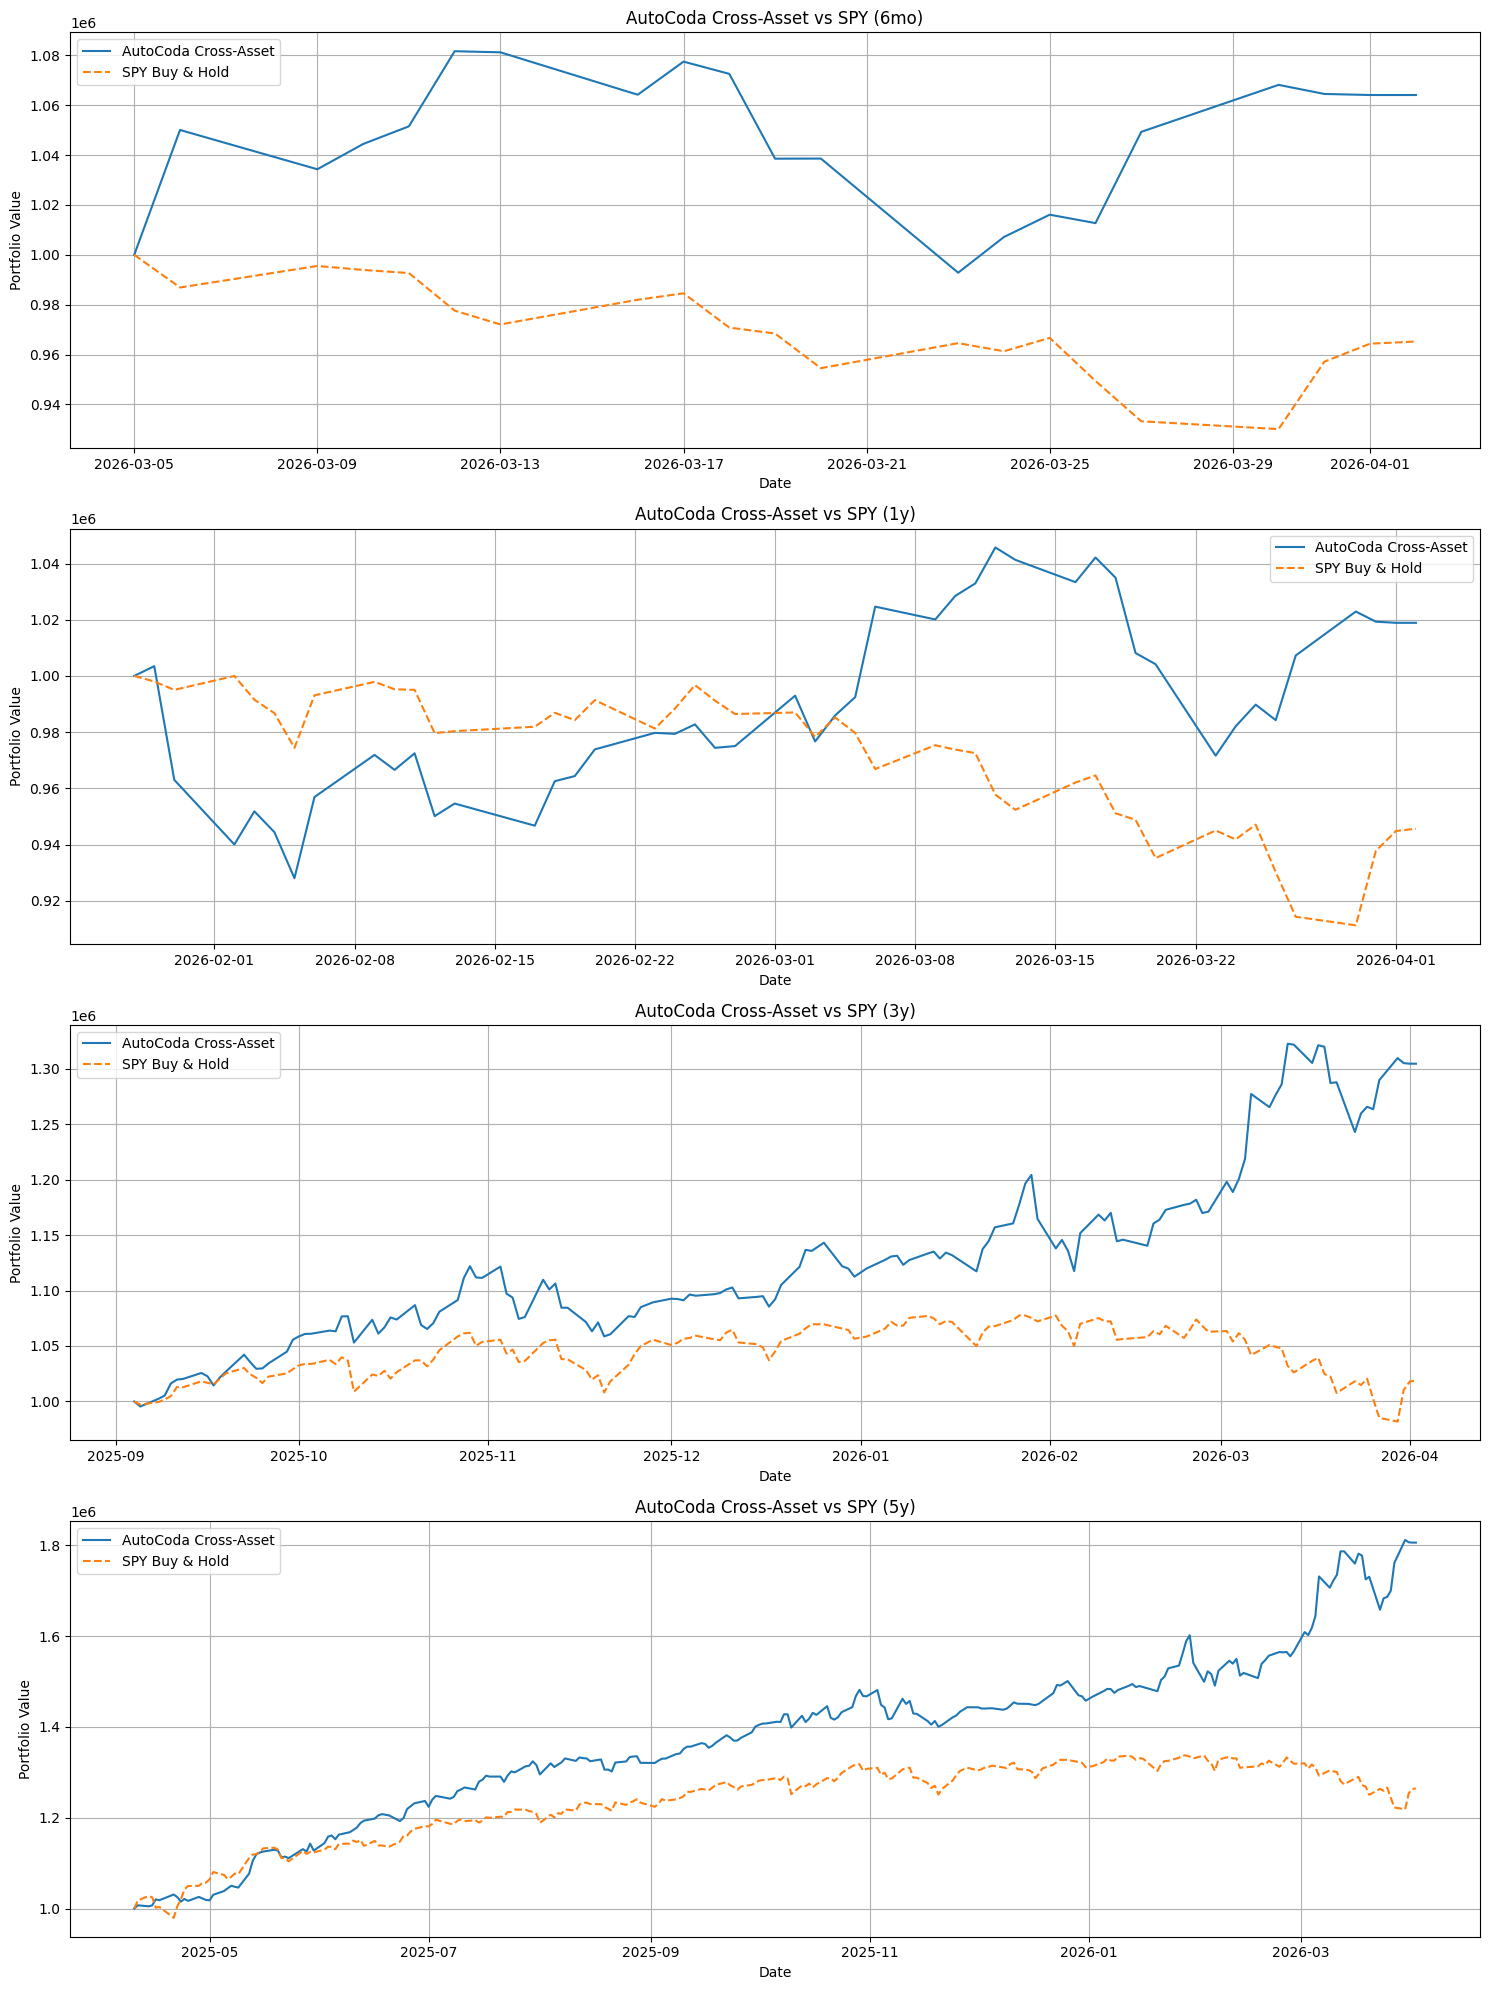

In [10]:
valid_periods = [p for p in HORIZONS if p in all_results]

fig, axes = plt.subplots(len(valid_periods), 1, figsize=(15, 5 * max(1, len(valid_periods))))
if len(valid_periods) == 1:
    axes = [axes]

for ax, period in zip(axes, valid_periods):
    result = all_results[period]
    ax.plot(result["portfolio_equity"].index, result["portfolio_equity"], label="AutoCoda Cross-Asset")
    ax.plot(result["spy_equity"].index, result["spy_equity"], label="SPY Buy & Hold", linestyle="--")
    ax.set_title(f"AutoCoda Cross-Asset vs SPY ({period})")
    ax.set_xlabel("Date")
    ax.set_ylabel("Portfolio Value")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()


## Inspect one horizon in detail

In [11]:
DETAIL_PERIOD = "5y" if "5y" in all_results else (list(all_results.keys())[0] if all_results else None)
DETAIL_PERIOD


'5y'

Detail period: 5y


,Strategy,Final Value,Total Return %,Annualized Return %,Annualized Vol %,Max Drawdown %,Sharpe (naive)
0,AutoCoda Cross-Asset,"1,805,889.6934",80.5890,86.4389,17.3884,-7.1947,3.5869
1,SPY Buy & Hold,"1,264,531.8342",26.4532,28.4181,13.2398,-8.8850,1.8901


,Ticker,Rows,Train Size,Test Size,Final Loss
0,SPY,1237,989,248,13.6892
1,NVDA,1237,989,248,1.9713
2,USO,1237,989,248,0.1353
3,GLD,1237,989,248,3.0020
4,DX-Y.NYB,1239,991,248,0.0010
5,TLT,1237,989,248,0.0031


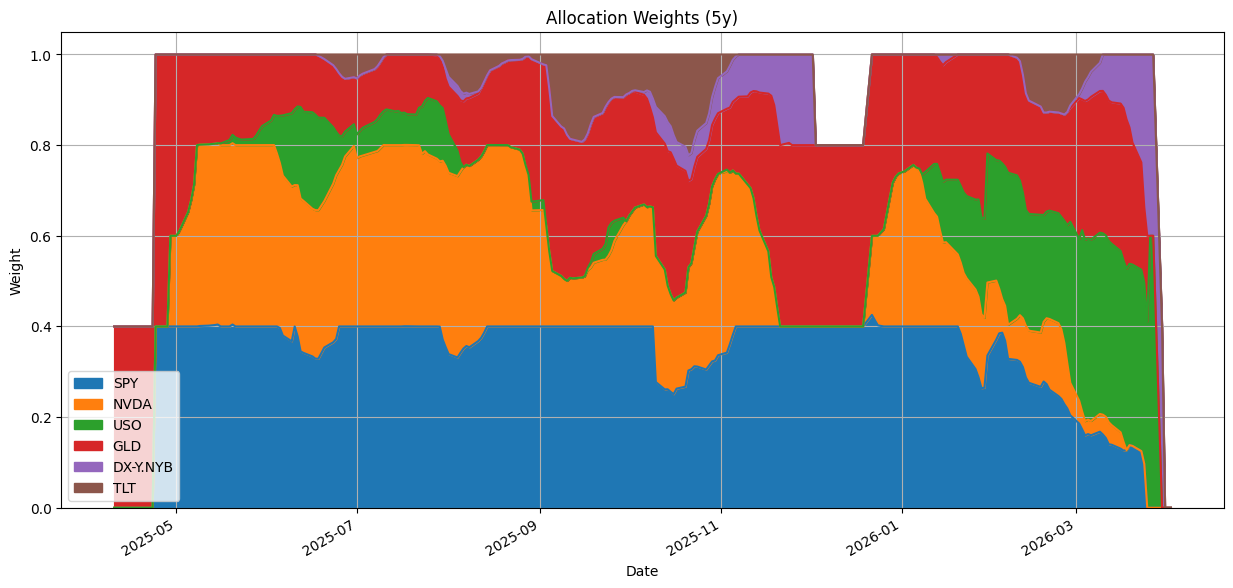

,count,mean,std,min,25%,50%,75%,max
Gross Exposure,246.0000,0.9528,0.1638,0.0000,1.0000,1.0000,1.0000,1.0000
Cash Weight,246.0000,0.0472,0.1638,-0.0000,0.0000,0.0000,0.0000,1.0000


In [12]:
if DETAIL_PERIOD is not None:
    detail = all_results[DETAIL_PERIOD]
    print("Detail period:", DETAIL_PERIOD)
    display(detail["summary"])
    display(detail["asset_run_log"])

    fig, ax = plt.subplots(figsize=(15, 7))
    detail["weight_matrix"].plot.area(ax=ax)
    ax.set_title(f"Allocation Weights ({DETAIL_PERIOD})")
    ax.set_xlabel("Date")
    ax.set_ylabel("Weight")
    ax.grid(True)
    plt.show()

    exposure_df = pd.DataFrame({
        "Gross Exposure": detail["gross_exposure"],
        "Cash Weight": 1.0 - detail["gross_exposure"],
    })
    display(exposure_df.describe().T)


## Save outputs

In [13]:
scoreboard.to_csv("autocoda_vs_spy_multi_horizon_scoreboard.csv", index=False)

for period, result in all_results.items():
    result["summary"].to_csv(f"summary_{period}.csv", index=False)
    result["weight_matrix"].to_csv(f"weights_{period}.csv")
    pd.DataFrame({
        "AutoCoda Cross-Asset": result["portfolio_equity"],
        "SPY Buy & Hold": result["spy_equity"],
    }).to_csv(f"equity_{period}.csv")

print("Saved scoreboard and per-horizon CSV outputs.")


Saved scoreboard and per-horizon CSV outputs.


## Interpretation checklist

After you run this, focus on:
1. Does AutoCoda beat SPY on all horizons, or only some?
2. Are wins accompanied by lower or higher drawdowns?
3. Does gross exposure stay at or below 1.0 at all times?
4. Does performance come from stable allocation or one concentrated phase?
5. If it loses on some horizons, is the loss caused by cash drag, late signal entry, or strong SPY trend dominance?


In [14]:
import numpy as np
import pandas as pd

def run_top1_momentum_horizon(
    period,
    lookback=63,  # ~3 months of trading days
    initial_capital=INITIAL_CAPITAL,
    transaction_cost_pct=TRANSACTION_COST_PCT,
):
    # Download the same asset universe
    asset_data = {}
    for ticker in ASSETS.keys():
        raw = download_price_data(ticker, period)
        df = add_indicators(raw)
        if len(df) < max(MIN_BARS_REQUIRED, lookback + 5):
            raise ValueError(f"Not enough usable rows for {ticker} over {period}")
        asset_data[ticker] = df

    # Align on common dates
    common_dates = None
    for ticker, df in asset_data.items():
        idx = df.index
        common_dates = idx if common_dates is None else common_dates.intersection(idx)

    common_dates = pd.Index(common_dates).sort_values()
    if len(common_dates) < lookback + 10:
        raise ValueError(f"Too few common dates for {period}")

    price_matrix = pd.DataFrame({
        ticker: asset_data[ticker]["Price"].reindex(common_dates)
        for ticker in asset_data
    })

    # Use same out-of-sample split style as AutoCoda
    split = int((1 - TEST_SIZE) * len(price_matrix))
    price_matrix = price_matrix.iloc[split:].copy()

    # Daily returns
    return_matrix = price_matrix.pct_change().fillna(0.0)

    # Trailing momentum: trailing return over lookback
    momentum = price_matrix / price_matrix.shift(lookback) - 1.0

    # Top-1 asset each day
    top_asset = momentum.idxmax(axis=1)

    # Build 1x weight matrix: 100% in best asset, 0% elsewhere
    weights = pd.DataFrame(0.0, index=price_matrix.index, columns=price_matrix.columns)
    for dt, asset in top_asset.dropna().items():
        weights.loc[dt, asset] = 1.0

    # Avoid same-day lookahead
    applied_weights = weights.shift(1).fillna(0.0)

    # 1x capital guard
    gross_exposure = applied_weights.sum(axis=1)
    assert not (gross_exposure > 1.000001).any(), "Top-1 momentum exceeded 1x exposure."

    # Returns and cost
    gross_portfolio_return = (applied_weights * return_matrix).sum(axis=1)
    turnover = applied_weights.diff().abs().sum(axis=1).fillna(0.0)
    cost_drag = turnover * (transaction_cost_pct / 100.0)
    net_portfolio_return = gross_portfolio_return - cost_drag

    equity = initial_capital * (1.0 + net_portfolio_return).cumprod()

    return {
        "period": period,
        "price_matrix": price_matrix,
        "momentum": momentum,
        "top_asset": top_asset,
        "weights": applied_weights,
        "gross_exposure": gross_exposure,
        "equity": equity,
    }


def compare_autocoda_vs_top1(period, lookback=63):
    # AutoCoda result from your existing notebook function
    autocoda = run_cross_asset_horizon(period)

    # Top-1 momentum
    top1 = run_top1_momentum_horizon(period, lookback=lookback)

    # Align all curves to common dates
    common_idx = autocoda["portfolio_equity"].index.intersection(top1["equity"].index).intersection(autocoda["spy_equity"].index)

    autocoda_eq = autocoda["portfolio_equity"].reindex(common_idx)
    top1_eq = top1["equity"].reindex(common_idx)
    spy_eq = autocoda["spy_equity"].reindex(common_idx)

    comparison = pd.DataFrame({
        "AutoCoda Cross-Asset": autocoda_eq,
        "Top-1 Momentum": top1_eq,
        "SPY Buy & Hold": spy_eq,
    })

    summary = pd.DataFrame([
        summarize_equity("AutoCoda Cross-Asset", autocoda_eq),
        summarize_equity("Top-1 Momentum", top1_eq),
        summarize_equity("SPY Buy & Hold", spy_eq),
    ]).sort_values("Total Return %", ascending=False).reset_index(drop=True)

    return {
        "period": period,
        "comparison": comparison,
        "summary": summary,
        "autocoda": autocoda,
        "top1": top1,
    }

In [15]:
result = compare_autocoda_vs_top1("5y", lookback=63)
result["summary"]

,Strategy,Final Value,Total Return %,Annualized Return %,Annualized Vol %,Max Drawdown %,Sharpe (naive)
0,Top-1 Momentum,"2,166,943.9341",116.6944,135.5955,36.3140,-13.8677,2.3638
1,AutoCoda Cross-Asset,"1,767,928.9833",76.7929,81.9434,17.2781,-7.9782,3.4682
2,SPY Buy & Hold,"1,268,388.2627",26.8388,28.6887,13.2144,-8.8850,1.9097


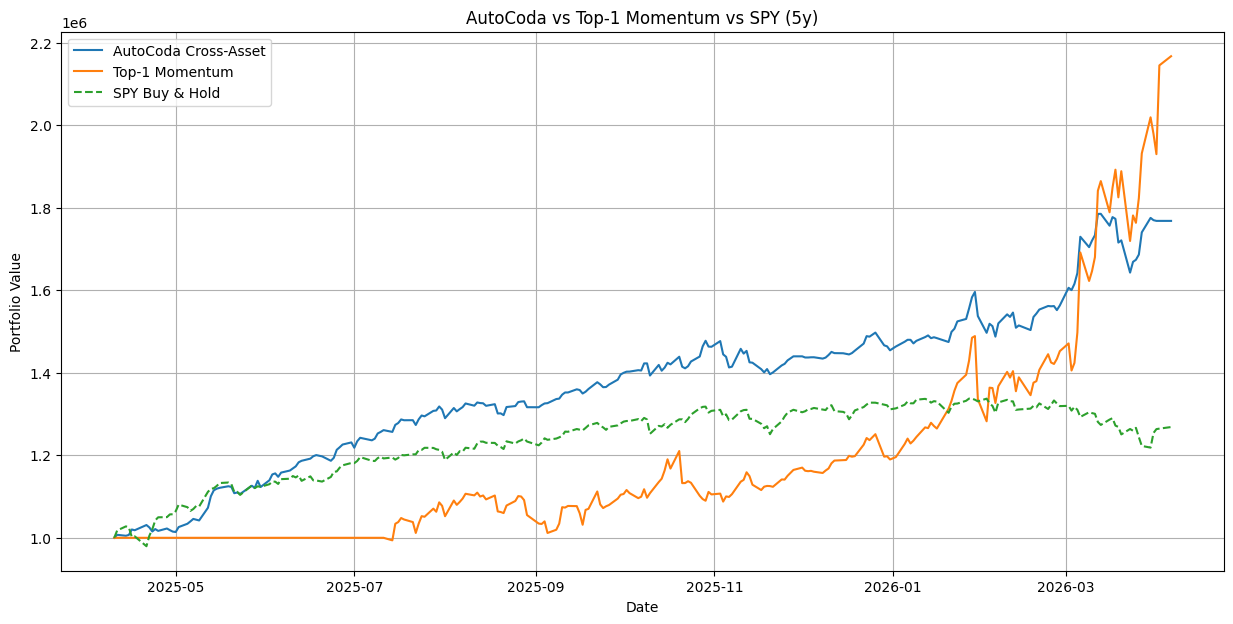

In [16]:
import matplotlib.pyplot as plt

cmp = result["comparison"]

fig, ax = plt.subplots(figsize=(15, 7))
ax.plot(cmp.index, cmp["AutoCoda Cross-Asset"], label="AutoCoda Cross-Asset")
ax.plot(cmp.index, cmp["Top-1 Momentum"], label="Top-1 Momentum")
ax.plot(cmp.index, cmp["SPY Buy & Hold"], label="SPY Buy & Hold", linestyle="--")
ax.set_title(f'AutoCoda vs Top-1 Momentum vs SPY ({result["period"]})')
ax.set_xlabel("Date")
ax.set_ylabel("Portfolio Value")
ax.grid(True)
ax.legend()
plt.show()

In [17]:
result["top1"]["top_asset"].value_counts()

GLD     103
NVDA     58
USO      24
Name: count, dtype: int64

In [18]:
def run_equal_weight_horizon(period):
    asset_data = {}
    for ticker in ASSETS.keys():
        raw = download_price_data(ticker, period)
        df = add_indicators(raw)
        asset_data[ticker] = df

    # Align dates
    common_dates = None
    for df in asset_data.values():
        common_dates = df.index if common_dates is None else common_dates.intersection(df.index)
    common_dates = pd.Index(common_dates).sort_values()

    price_matrix = pd.DataFrame({
        ticker: asset_data[ticker]["Price"].reindex(common_dates)
        for ticker in asset_data
    })

    split = int((1 - TEST_SIZE) * len(price_matrix))
    price_matrix = price_matrix.iloc[split:]

    returns = price_matrix.pct_change().fillna(0.0)

    N = len(price_matrix.columns)
    weights = pd.DataFrame(1.0 / N, index=price_matrix.index, columns=price_matrix.columns)

    portfolio_return = (weights.shift(1) * returns).sum(axis=1)
    equity = INITIAL_CAPITAL * (1 + portfolio_return).cumprod()

    return equity

def run_inverse_vol_horizon(period, vol_lookback=20):
    asset_data = {}
    for ticker in ASSETS.keys():
        raw = download_price_data(ticker, period)
        df = add_indicators(raw)
        asset_data[ticker] = df

    common_dates = None
    for df in asset_data.values():
        common_dates = df.index if common_dates is None else common_dates.intersection(df.index)
    common_dates = pd.Index(common_dates).sort_values()

    price_matrix = pd.DataFrame({
        ticker: asset_data[ticker]["Price"].reindex(common_dates)
        for ticker in asset_data
    })

    split = int((1 - TEST_SIZE) * len(price_matrix))
    price_matrix = price_matrix.iloc[split:]

    returns = price_matrix.pct_change().fillna(0.0)

    vol = returns.rolling(vol_lookback).std()

    inv_vol = 1.0 / vol.replace(0, np.nan)
    weights = inv_vol.div(inv_vol.sum(axis=1), axis=0).fillna(0)

    portfolio_return = (weights.shift(1) * returns).sum(axis=1)
    equity = INITIAL_CAPITAL * (1 + portfolio_return).cumprod()

    return equity

def run_momentum_horizon(period, lookback=63):
    asset_data = {}
    for ticker in ASSETS.keys():
        raw = download_price_data(ticker, period)
        df = add_indicators(raw)
        asset_data[ticker] = df

    common_dates = None
    for df in asset_data.values():
        common_dates = df.index if common_dates is None else common_dates.intersection(df.index)
    common_dates = pd.Index(common_dates).sort_values()

    price_matrix = pd.DataFrame({
        ticker: asset_data[ticker]["Price"].reindex(common_dates)
        for ticker in asset_data
    })

    split = int((1 - TEST_SIZE) * len(price_matrix))
    price_matrix = price_matrix.iloc[split:]

    returns = price_matrix.pct_change().fillna(0.0)

    momentum = price_matrix / price_matrix.shift(lookback) - 1

    # only positive momentum
    momentum = momentum.clip(lower=0)

    weights = momentum.div(momentum.sum(axis=1), axis=0).fillna(0)

    portfolio_return = (weights.shift(1) * returns).sum(axis=1)
    equity = INITIAL_CAPITAL * (1 + portfolio_return).cumprod()

    return equity

In [19]:
def compare_all_strategies(period):
    autocoda = run_cross_asset_horizon(period)

    eq = run_equal_weight_horizon(period)
    iv = run_inverse_vol_horizon(period)
    mom = run_momentum_horizon(period)

    common_idx = autocoda["portfolio_equity"].index

    df = pd.DataFrame({
        "AutoCoda": autocoda["portfolio_equity"].reindex(common_idx),
        "SPY": autocoda["spy_equity"].reindex(common_idx),
        "Equal Weight": eq.reindex(common_idx),
        "Inverse Vol": iv.reindex(common_idx),
        "Momentum": mom.reindex(common_idx),
    })

    summary = pd.DataFrame([
        summarize_equity("AutoCoda", df["AutoCoda"]),
        summarize_equity("SPY", df["SPY"]),
        summarize_equity("Equal Weight", df["Equal Weight"]),
        summarize_equity("Inverse Vol", df["Inverse Vol"]),
        summarize_equity("Momentum", df["Momentum"]),
    ]).sort_values("Total Return %", ascending=False)

    return df, summary

In [20]:
df, summary = compare_all_strategies("5y")

summary

,Strategy,Final Value,Total Return %,Annualized Return %,Annualized Vol %,Max Drawdown %,Sharpe (naive)
0,AutoCoda,"1,794,402.3098",79.4402,84.8926,17.7730,-8.0187,3.4623
4,Momentum,"1,712,375.4420",71.2375,79.9924,27.2701,-11.5342,2.1578
2,Equal Weight,"1,374,248.1095",41.1720,43.1517,10.5365,-4.4548,3.4071
1,SPY,"1,269,005.1322",26.9005,28.7529,13.2153,-8.8850,1.9133
3,Inverse Vol,"1,182,277.1459",18.2277,18.8944,5.5612,-2.7969,3.1131


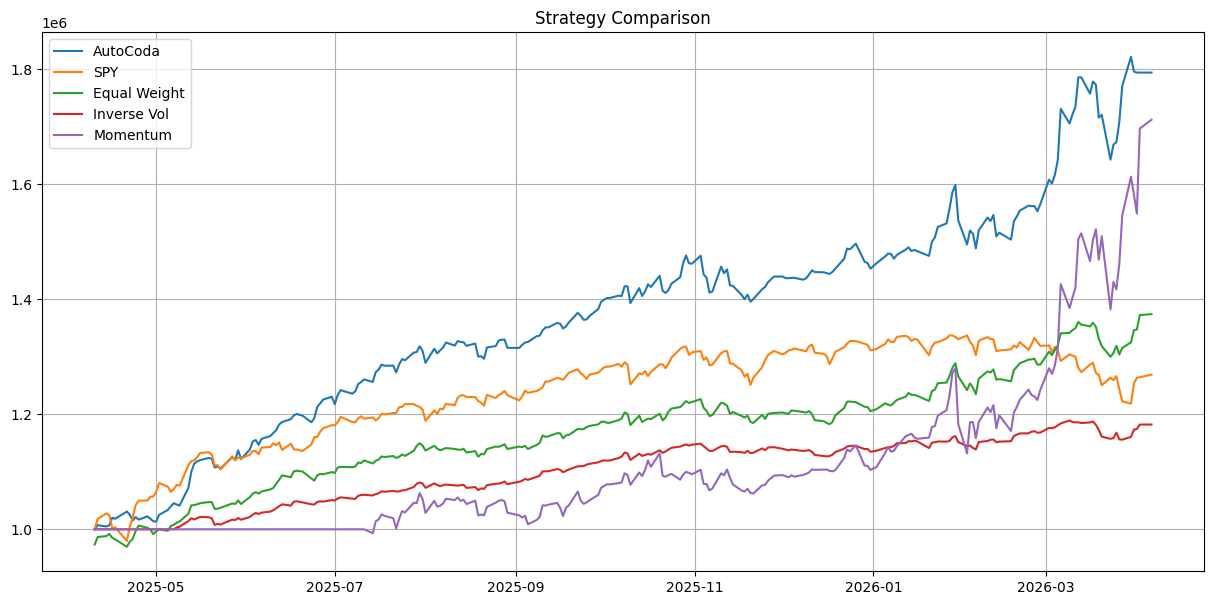

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,7))
for col in df.columns:
    plt.plot(df.index, df[col], label=col)

plt.legend()
plt.title("Strategy Comparison")
plt.grid(True)
plt.show()